# Model 2: Czy da się przewidzieć, że utwór stanie się viralem?
### Klasyfikacja binarna – część praktyczna

**Zadanie:** na podstawie cech audio przewidzieć, czy utwór jest viralem (`viral = 1`), czy nie (`viral = 0`).

Schemat pracy znamy z regresji: przygotowanie danych → podział train/test → baseline → modele → ocena na zbiorze testowym. Tym razem przewidujemy kategorię, więc zamiast R² patrzymy na accuracy, precision, recall i AUC.

| | Część A – omówienie | | Część B – zadania |
|---|---|---|---|
| 1 | Dane i podział train/test | Z1 | Wyciek danych |
| 2 | Baseline | Z2 | Precision i recall |
| 3 | Regresja logistyczna: macierz pomyłek i raport | | |
| 4 | Pięć klasyfikatorów w jednej pętli | | |
| 5 | Przeuczenie drzewa decyzyjnego | | |
| 6 | Krzywa ROC i AUC | | |
| 7 | Które cechy są ważne? | | |
| 8 | Wnioski | | |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn import (model_selection, linear_model, tree, neighbors, svm,
                     ensemble, metrics, preprocessing, pipeline, dummy)

RANDOM_STATE = 42   # ta sama liczba = te same wyniki przy każdym uruchomieniu
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

## 1. Dane i podział na zbiór treningowy i testowy

Z EDA pamiętamy: **64% utworów to nie-viral, 36% to viral**, a viralowość mocno zależy od gatunku.

| Kolumna | Bierzemy? | Dlaczego |
|---|---|---|
| cechy audio (`danceability`, `energy`, …) | ✅ | pytanie brzmi: czy *dźwięk* przewiduje virala |
| `track_id`, `track_name`, `artist` | ❌ | identyfikatory |
| `streams` | ❌ | **wyciek danych**: przed premierą nie znamy liczby odsłuchań (sprawdzimy to w zadaniu Z1) |

`stratify=y` pilnuje, żeby w treningu i teście był taki sam odsetek viral hitów.

In [2]:
# Szukamy pliku lokalnie; jeśli go nie ma (np. Google Colab) – pobieramy z GitHuba
URL = "https://raw.githubusercontent.com/mzntk/ml-seminarium-projekt/main/dane/viral_songs.csv"
kandydaci = [Path("../dane/viral_songs.csv"), Path("dane/viral_songs.csv"), Path("../../dane/viral_songs.csv")]
sciezka = next((p for p in kandydaci if p.exists()), URL)

df = pd.read_csv(sciezka)
print("Wczytano z:", sciezka)
print("Rozmiar tabeli (wiersze, kolumny):", df.shape)
df.head()

Wczytano z: ../../dane/viral_songs.csv
Rozmiar tabeli (wiersze, kolumny): (10000, 17)


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [3]:
CECHY_AUDIO = ["duration_sec", "danceability", "energy", "valence", "tempo_bpm",
               "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db"]

X = df[CECHY_AUDIO]
y = df["viral"]

X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, train_size=0.7, stratify=y, random_state=RANDOM_STATE)

print("Zbiór treningowy:", X_train.shape, "| zbiór testowy:", X_test.shape)
print("Odsetek viral – trening:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Zbiór treningowy: (7000, 10) | zbiór testowy: (3000, 10)
Odsetek viral – trening: 0.361 | test: 0.36


## 2. Baseline

`DummyClassifier` zawsze odpowiada najczęstszą klasą („nie viral”).

In [4]:
baseline = dummy.DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print("Accuracy baseline:", round(metrics.accuracy_score(y_test, y_pred_base), 3))
print("Ile viral hitów wyłapał (recall):", metrics.recall_score(y_test, y_pred_base))

Accuracy baseline: 0.64
Ile viral hitów wyłapał (recall): 0.0


**64% trafności bez żadnej wiedzy**, a przy tym ani jeden wyłapany viral. Każdy model musi być wyraźnie lepszy niż 0.64, a samo accuracy nie wystarczy.

## 3. Regresja logistyczna: macierz pomyłek i raport

Jak w regresji, `make_pipeline` skleja skalowanie z modelem.

In [5]:
model_lr = pipeline.make_pipeline(
    preprocessing.StandardScaler(),         # krok 1: skalowanie cech
    linear_model.LogisticRegression())      # krok 2: właściwy model

model_lr.fit(X_train, y_train)              # nauka
y_pred_lr = model_lr.predict(X_test)        # przewidywanie

print("Accuracy:", round(metrics.accuracy_score(y_test, y_pred_lr), 3))

Accuracy: 0.714


### Macierz pomyłek

| | przewidziano 0 | przewidziano 1 |
|---|---|---|
| **naprawdę 0** | trafione „nie viral” | **fałszywy alarm** |
| **naprawdę 1** | **przeoczony viral** | trafiony viral |

[[1571  348]
 [ 511  570]]


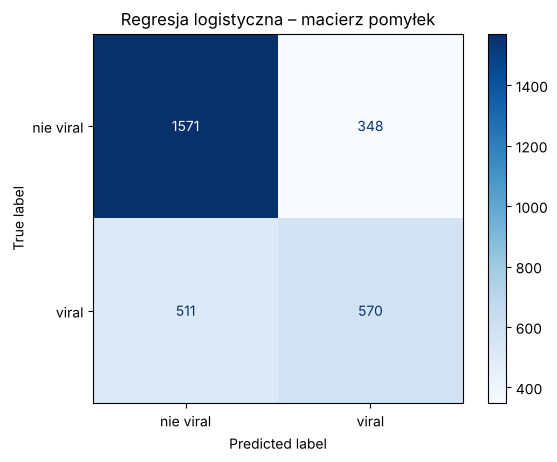

In [6]:
cm = metrics.confusion_matrix(y_test, y_pred_lr)
print(cm)

metrics.ConfusionMatrixDisplay(cm, display_labels=["nie viral", "viral"]).plot(cmap="Blues")
plt.title("Regresja logistyczna – macierz pomyłek")
plt.show()

Model trafił 570 viral hitów, ale **511 przeoczył** i zrobił 348 fałszywych alarmów.

### Raport klasyfikacji

- **precision** – ile z utworów nazwanych viralami naprawdę nimi było,
- **recall** – ile prawdziwych viral hitów model wyłapał,
- **f1-score** – jedna liczba łącząca obie,
- **support** – liczba utworów danej klasy w zbiorze testowym.

In [7]:
print(metrics.classification_report(y_test, y_pred_lr, target_names=["nie viral (0)", "viral (1)"]))

               precision    recall  f1-score   support

nie viral (0)       0.75      0.82      0.79      1919
    viral (1)       0.62      0.53      0.57      1081

     accuracy                           0.71      3000
    macro avg       0.69      0.67      0.68      3000
 weighted avg       0.71      0.71      0.71      3000



Dla klasy „viral”: precision 0.62, recall 0.53. Model wyłapuje nieco ponad połowę hitów, a prawie 4 na 10 jego „viral” to pomyłki.

## 4. Pięć klasyfikatorów w jednej pętli

Zmieniamy tylko model, reszta kodu zostaje ta sama. Skalowanie dodajemy tam, gdzie model liczy odległości lub wagi (regresja logistyczna, k-NN, SVC). Drzewom i lasowi nie jest potrzebne.

Liczymy też **accuracy na zbiorze treningowym**: duża różnica między treningiem a testem oznacza przeuczenie.

In [8]:
modele = {
    "LogisticRegression": pipeline.make_pipeline(preprocessing.StandardScaler(),
                                                 linear_model.LogisticRegression()),
    "DecisionTree":       tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNeighbors":         pipeline.make_pipeline(preprocessing.StandardScaler(),
                                                 neighbors.KNeighborsClassifier()),
    "SVC":                pipeline.make_pipeline(preprocessing.StandardScaler(),
                                                 svm.SVC(random_state=RANDOM_STATE)),
    "RandomForest":       ensemble.RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}


def wynik_ciagly(model, X):
    """'Pewność' modelu, że utwór jest viralem – potrzebna do AUC (punkt 6).
    SVC domyślnie nie liczy prawdopodobieństw, ale ma decision_function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


wyniki = []
for nazwa, model in modele.items():
    model.fit(X_train, y_train)                 # ten sam kod dla każdego modelu!
    y_pred = model.predict(X_test)
    wyniki.append({
        "model": nazwa,
        "accuracy (trening)": metrics.accuracy_score(y_train, model.predict(X_train)),
        "accuracy (test)":    metrics.accuracy_score(y_test, y_pred),
        "precision":          metrics.precision_score(y_test, y_pred),
        "recall":             metrics.recall_score(y_test, y_pred),
        "F1":                 metrics.f1_score(y_test, y_pred),
        "AUC":                metrics.roc_auc_score(y_test, wynik_ciagly(model, X_test)),
    })

tabela = pd.DataFrame(wyniki).set_index("model").round(3)
tabela

,accuracy (trening),accuracy (test),precision,recall,F1,AUC
model,,,,,,
LogisticRegression,0.707,0.714,0.621,0.527,0.570,0.789
DecisionTree,1.000,0.633,0.490,0.496,0.493,0.603
KNeighbors,0.782,0.659,0.528,0.489,0.508,0.700
SVC,0.741,0.709,0.616,0.507,0.556,0.759
RandomForest,1.000,0.704,0.605,0.513,0.556,0.768


**Co widać w tabeli?**

- Modele są lepsze od baseline’u (0.64), ale **niewiele**: najlepsze mają accuracy ok. 0.71.
- Najlepiej wypada **najprostsza regresja logistyczna** (AUC ≈ 0.79). SVC i las losowy są tuż za nią.
- **Drzewo decyzyjne ma 100% na treningu, a na teście jest gorsze niż baseline** (0.63). To przeuczenie (punkt 5). Las losowy też ma 100% na treningu, ale dzięki głosowaniu wielu drzew na teście radzi sobie dobrze.
- Recall dla klasy „viral” jest u wszystkich ok. 0.5: modele przeoczają mniej więcej co drugi hit.

## 5. Przeuczenie drzewa decyzyjnego

Ograniczamy głębokość drzewa (`max_depth`) i porównujemy wynik na treningu i teście:

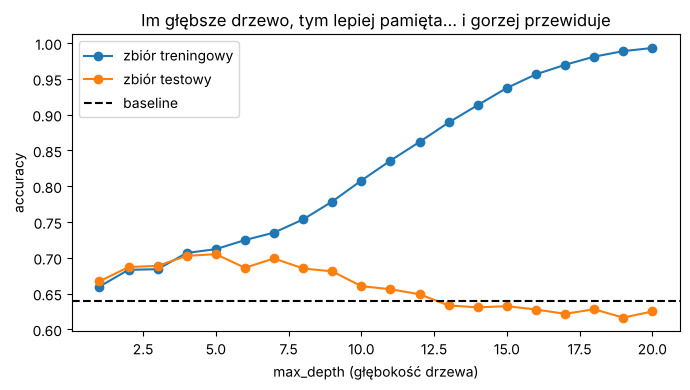

Najlepsza głębokość na teście: 5


In [9]:
glebokosci = range(1, 21)
acc_trening, acc_test = [], []
for d in glebokosci:
    drzewo = tree.DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    drzewo.fit(X_train, y_train)
    acc_trening.append(drzewo.score(X_train, y_train))   # .score = accuracy
    acc_test.append(drzewo.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(glebokosci, acc_trening, "o-", label="zbiór treningowy")
plt.plot(glebokosci, acc_test, "o-", label="zbiór testowy")
plt.axhline(0.64, color="black", ls="--", label="baseline")
plt.xlabel("max_depth (głębokość drzewa)")
plt.ylabel("accuracy")
plt.title("Im głębsze drzewo, tym lepiej pamięta… i gorzej przewiduje")
plt.legend()
plt.tight_layout()
plt.show()

print("Najlepsza głębokość na teście:", glebokosci[int(np.argmax(acc_test))])

Na treningu wynik rośnie aż do 100%, a na teście najpierw rośnie, potem **spada**. Najlepiej działa płytkie drzewo (głębokość ok. 5). To ten sam efekt co przy lesie losowym w regresji.

## 6. Krzywa ROC i AUC

Krzywa ROC pokazuje kompromis między wyłapanymi viralami (oś Y) a fałszywymi alarmami (oś X) dla wszystkich możliwych progów decyzyjnych. Im bliżej lewego górnego rogu, tym lepiej. Przekątna to losowe zgadywanie (AUC = 0.5).

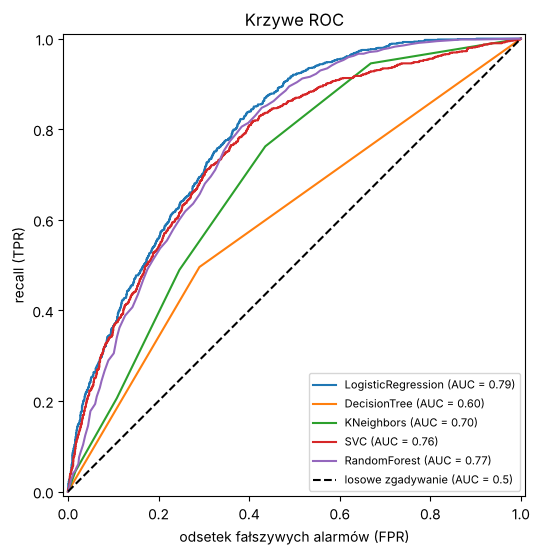

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
for nazwa, model in modele.items():
    metrics.RocCurveDisplay.from_predictions(y_test, wynik_ciagly(model, X_test), name=nazwa, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="losowe zgadywanie (AUC = 0.5)")
ax.set_xlabel("odsetek fałszywych alarmów (FPR)")
ax.set_ylabel("recall (TPR)")
ax.set_title("Krzywe ROC")
ax.legend(loc="lower right", fontsize=8)
plt.show()

Kolejność modeli jest taka sama jak w tabeli: regresja logistyczna (0.79), las losowy i SVC (ok. 0.76–0.77), k-NN (0.70), drzewo (0.60).

## 7. Które cechy są ważne?

Po lewej współczynniki regresji logistycznej (zielone podnoszą szansę na virala, czerwone obniżają), po prawej ważność cech w lesie losowym.

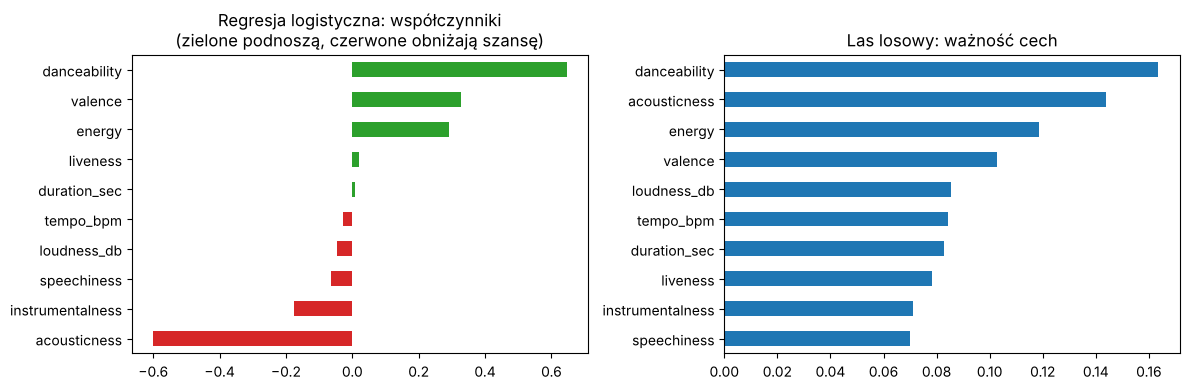

Mnożniki szans (odds ratio) z regresji logistycznej:
danceability        1.91
valence             1.39
energy              1.34
liveness            1.02
duration_sec        1.01
tempo_bpm           0.97
loudness_db         0.96
speechiness         0.94
instrumentalness    0.84
acousticness        0.55
dtype: float64


In [11]:
wspolczynniki = pd.Series(model_lr.named_steps["logisticregression"].coef_[0], index=CECHY_AUDIO)
waznosci = pd.Series(modele["RandomForest"].feature_importances_, index=CECHY_AUDIO)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wspolczynniki.sort_values().plot.barh(ax=axes[0],
    color=["tab:red" if w < 0 else "tab:green" for w in wspolczynniki.sort_values()])
axes[0].set_title("Regresja logistyczna: współczynniki\n(zielone podnoszą, czerwone obniżają szansę)")
waznosci.sort_values().plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Las losowy: ważność cech")
plt.tight_layout()
plt.show()

print("Mnożniki szans (odds ratio) z regresji logistycznej:")
print(np.exp(wspolczynniki).sort_values(ascending=False).round(2))

Oba modele zgadzają się co do najważniejszych cech: **`danceability`, `acousticness`, `energy`, `valence`**, czyli tych samych, które w EDA były najsilniej skorelowane z `viral`. Wzrost taneczności o jedno odchylenie standardowe mniej więcej **podwaja** szanse na virala (mnożnik 1.91), a akustyczność **zmniejsza je prawie o połowę** (0.55).

## 8. Wnioski

**Czy da się przewidzieć, że utwór stanie się viralem?** Częściowo.

- Najlepszy model (regresja logistyczna) osiąga **AUC ≈ 0.79** i accuracy ≈ 0.71, wobec 0.64 dla baseline’u.
- Przy domyślnym progu modele **przeoczają mniej więcej co drugi hit**.
- Viral hity są **taneczne, energetyczne, pogodne i nieakustyczne**.
- Reszta zależy od czynników, których nie ma w danych (marketing, popularność artysty, przypadek).

**Praktyczne lekcje:**
1. Wynik zawsze porównujemy z baseline’em.
2. Przy niezrównoważonych klasach samo accuracy myli: patrzymy na precision, recall i AUC.
3. Wynik na treningu nic nie znaczy (drzewo: 100%). Liczy się zbiór testowy.
4. Uwaga na wyciek danych (`streams`).

---
# Część B – zadania

Uzupełnij miejsca oznaczone `___`. Komórki korzystają ze zmiennych z części A.

## Zadanie 1 – Wyciek danych

Dodaj kolumnę `streams` do cech, wytrenuj las losowy i porównaj jego AUC z wynikiem bez `streams`.

In [12]:
X_wyciek = df[CECHY_AUDIO + ["streams"]]

Xw_train, Xw_test, yw_train, yw_test = model_selection.train_test_split(
    X_wyciek, y, train_size=0.7, stratify=y, random_state=RANDOM_STATE)

model_wyciek = ensemble.RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
model_wyciek.fit(Xw_train, yw_train)

auc_wyciek = metrics.roc_auc_score(yw_test, model_wyciek.predict_proba(Xw_test)[:, 1])
print("AUC ze 'streams':", round(auc_wyciek, 3))
print("AUC bez 'streams':", tabela.loc["RandomForest", "AUC"])

AUC ze 'streams': 0.905
AUC bez 'streams': 0.768


## Zadanie 2 – Precision i recall

Model przetestowano na 100 utworach. Na podstawie jego macierzy pomyłek oblicz accuracy, precision i recall dla klasy „viral” i wpisz wyniki. Druga część komórki sprawdzi odpowiedzi.

| | przewidziano 0 | przewidziano 1 |
|---|---|---|
| **naprawdę 0** | 50 | 10 |
| **naprawdę 1** | 20 | 20 |

In [13]:
accuracy  = (50 + 20) / 100
precision = 20 / (20 + 10)
recall    = 20 / (20 + 20)

# --- sprawdzenie (nie zmieniaj) ---
y_true = np.array([0] * 60 + [1] * 40)
y_pred = np.array([0] * 50 + [1] * 10 + [0] * 20 + [1] * 20)
print("accuracy  OK" if np.isclose(accuracy,  metrics.accuracy_score(y_true, y_pred),  atol=0.01) else "accuracy  – spróbuj jeszcze raz")
print("precision OK" if np.isclose(precision, metrics.precision_score(y_true, y_pred), atol=0.01) else "precision – spróbuj jeszcze raz")
print("recall    OK" if np.isclose(recall,    metrics.recall_score(y_true, y_pred),    atol=0.01) else "recall    – spróbuj jeszcze raz")

accuracy  OK
precision OK
recall    OK
